In [1]:
import os
try:
    BASE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE = os.getcwd()
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from src.figures import save_figure
from IPython.display import HTML

warnings.simplefilter(action='ignore', category=FutureWarning)
plt.style.use(os.path.join(BASE,"..", "configs", "visualisations.mplstyle"))

from src.data_loader import _load_disaster_data

df = _load_disaster_data(BASE)

figure_path = os.path.join(BASE, '03_figures')
if not os.path.exists(figure_path):
    os.makedirs(figure_path)

# VL 03: Linear Regression

**Fig. 3.1** Line plus noise

Saved Fig. 3.1 -> 03_figures/3.1_line_plus_noise/3.1_line_plus_noise_No_Homeless_Total_Damages_US.pdf
Saved Fig. 3.1 -> 03_figures/3.1_line_plus_noise/3.1_line_plus_noise_No_Homeless_Total_Damages_US.svg


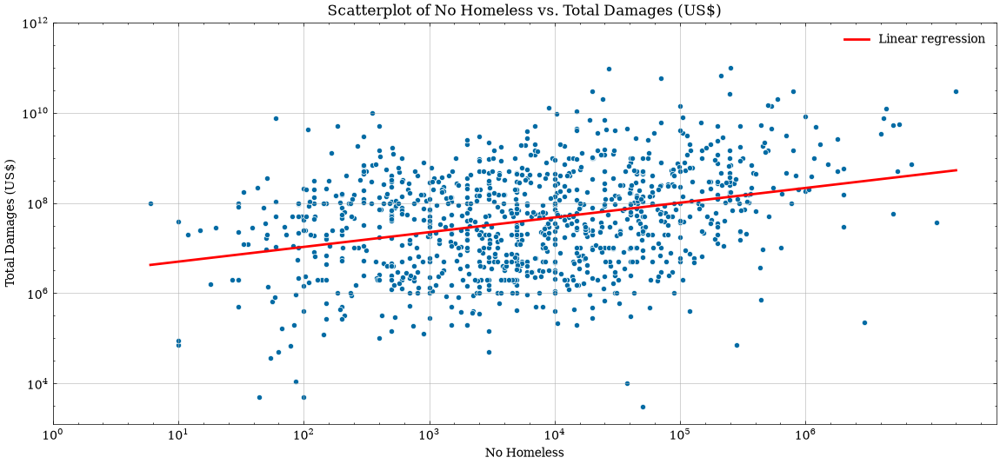

In [2]:
def _plot_scatter(df, x_axis, y_axis, fit_polyfit, n=2):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis])
    y = np.log10(df.loc[mask, y_axis])

    plt.scatter(x, y,s=20,marker='o', alpha=1,edgecolors='w', linewidth=0.5)

    if fit_polyfit:
        coefficients = np.polyfit(x, y, n)
        poly = np.poly1d(coefficients)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = poly(x_fit)
        plt.plot(x_fit, y_fit, color='red', linewidth=2, label=f'Linear regression')

    plt.xticks(ticks=np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]), labels=['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$', '$10^6$'])
    plt.yticks(ticks=np.log10([1e4, 1e6, 1e8, 1e10, 1e12]), labels=['$10^4$', '$10^6$', '$10^8$', '$10^{10}$', '$10^{12}$'])
    plt.legend()

    plt.xlabel(f'{x_axis}')
    plt.ylabel(f'{y_axis}')
    plt.title(f'Scatterplot of {x_axis} vs. {y_axis}')
    save_figure(3, 1, 'line_plus_noise', variant=f'{x_axis}_{y_axis}')
    plt.show()


x_axis = 'No Homeless'
y_axis = 'Total Damages (US$)'
fit_polyfit = True

_plot_scatter(df, x_axis=x_axis, y_axis=y_axis, fit_polyfit=fit_polyfit, n=1)

**Fig. 3.2** OLS fit (animation)

In [3]:
def animate_regression_lines(df, x_axis, y_axis,
                             n_slope=9, n_intercept=9,
                             slope_spread=0.3, intercept_spread=1.0, fps=8):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis].astype(float)).to_numpy()
    y = np.log10(df.loc[mask, y_axis].astype(float)).to_numpy()

    b1_true, b0_true = np.polyfit(x, y, 1)                       # true least-squares line
    b0_vals = b0_true + np.linspace(-intercept_spread, intercept_spread, n_intercept)
    b1_vals = b1_true + np.linspace(-slope_spread, slope_spread, n_slope)
    combos = [(b0, b1) for b0 in b0_vals for b1 in b1_vals]
    x_line = np.linspace(x.min(), x.max(), 100)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(x, y, s=20, marker='o', alpha=0.9, edgecolors='w', linewidth=0.5, zorder=1)

    cand_line, = ax.plot([], [], color='red', lw=2.5, zorder=3)
    txt = ax.text(0.03, 0.95, '', transform=ax.transAxes, va='top', fontsize=11,
                  family='monospace', bbox=dict(boxstyle='round', fc='white', alpha=0.8))

    ax.set_xticks(np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]))
    ax.set_xticklabels(['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$', '$10^6$'])
    ax.set_xlabel(x_axis); ax.set_ylabel(y_axis)
    ax.set_title(f'{y_axis} vs. {x_axis}'); ax.legend(loc='lower right')

    def update(i):
        b0, b1 = combos[i]
        cand_line.set_data(x_line, b0 + b1 * x_line)
        is_true = abs(b0 - b0_true) < 1e-9 and abs(b1 - b1_true) < 1e-9
        cand_line.set_color('green' if is_true else 'red')
        txt.set_text(f'b0 = {b0:6.2f}\nb1 = {b1:6.2f}')
        return cand_line, txt

    anim = FuncAnimation(fig, update, frames=len(combos), interval=1000/fps, blit=True)
    plt.close(fig)
    return anim

os.makedirs(os.path.join(figure_path,'3.2_ols_fit'),exist_ok=True)
anim = animate_regression_lines(df, 'No Homeless', 'Total Damages (US$)')
anim.save(os.path.join(figure_path,'3.2_ols_fit', '3.2_ols_fit.gif'), writer=PillowWriter(fps=8))

/var/folders/ct/qpfxjbdn1xx4fvb2v099sg_00000gn/T/ipykernel_26398/2760834551.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_title(f'{y_axis} vs. {x_axis}'); ax.legend(loc='lower right')


**Fig. 3.2** OLS fit (static)

Saved Fig. 3.2 -> 03_figures/3.2_ols_fit/3.2_ols_fit_No_Homeless_Total_Damages_US.pdf
Saved Fig. 3.2 -> 03_figures/3.2_ols_fit/3.2_ols_fit_No_Homeless_Total_Damages_US.svg


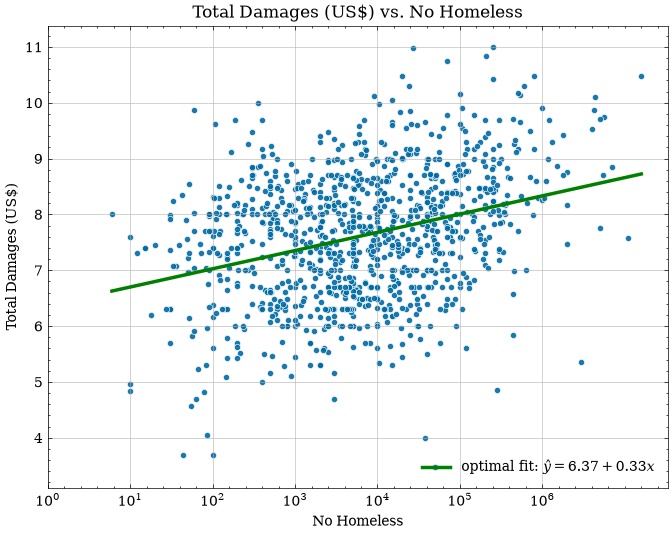

In [4]:
def plot_optimal_fit(df, x_axis, y_axis):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis].astype(float)).to_numpy()
    y = np.log10(df.loc[mask, y_axis].astype(float)).to_numpy()

    b1, b0 = np.polyfit(x, y, 1)                 # optimal least-squares line
    x_line = np.linspace(x.min(), x.max(), 100)

    plt.figure(figsize=(8, 6))
    plt.scatter(x, y, s=20, marker='o', alpha=0.9, edgecolors='w', linewidth=0.5)
    plt.plot(x_line, b0 + b1 * x_line, color='green', lw=2.5,
             label=f'optimal fit: $\\hat{{y}} = {b0:.2f} + {b1:.2f}x$')

    plt.xticks(np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]),
               ['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$', '$10^6$'])
    plt.xlabel(x_axis); plt.ylabel(y_axis)
    plt.title(f'{y_axis} vs. {x_axis}'); plt.legend(loc='lower right')
    save_figure(3, 2, 'ols_fit', variant=f'{x_axis}_{y_axis}')
    plt.show()

plot_optimal_fit(df, 'No Homeless', 'Total Damages (US$)')

**Fig. 3.3** RSS surface (landscape)

Saved Fig. 3.3 -> 03_figures/3.3_rss_surface/3.3_rss_surface_landscape.pdf
Saved Fig. 3.3 -> 03_figures/3.3_rss_surface/3.3_rss_surface_landscape.svg


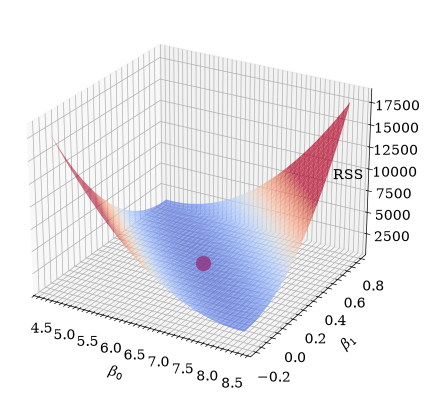

In [5]:
def plot_rss_landscape(df, x_axis, y_axis, b0_spread=2.0, b1_spread=0.5, n=120):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis].astype(float)).to_numpy()
    y = np.log10(df.loc[mask, y_axis].astype(float)).to_numpy()

    b1_hat, b0_hat = np.polyfit(x, y, 1)
    rss_min = np.sum((y - (b0_hat + b1_hat * x)) ** 2)

    b0 = np.linspace(b0_hat - b0_spread, b0_hat + b0_spread, n)
    b1 = np.linspace(b1_hat - b1_spread, b1_hat + b1_spread, n)
    B0, B1 = np.meshgrid(b0, b1)
    resid = y[:, None, None] - (B0[None] + B1[None] * x[:, None, None])
    RSS = np.sum(resid ** 2, axis=0)

    fig = plt.figure(figsize=(12, 5))
    axR = fig.add_subplot(1, 1, 1 , projection='3d')

    
    levels = rss_min * np.array([1.002, 1.01, 1.03, 1.07, 1.15, 1.3, 1.6])
    axR.plot_surface(B0, B1, RSS,vmin=rss_min/2, vmax=RSS.max()/2, cmap='coolwarm', edgecolor='none', alpha=0.7)
    axR.scatter([b0_hat], [b1_hat], [rss_min+100], color='red', s=100)
    axR.set_xlabel(r'$\beta_0$'); axR.set_ylabel(r'$\beta_1$')
    axR.set_zlabel('RSS', labelpad=-30)
    
    axR.view_init(elev=25, azim=-60)
    save_figure(3, 3, 'rss_surface', variant='landscape')
    plt.show()

plot_rss_landscape(df, 'No Homeless', 'Total Damages (US$)')

**Fig. 3.3** RSS surface (contour)

Saved Fig. 3.3 -> 03_figures/3.3_rss_surface/3.3_rss_surface_contour.pdf
Saved Fig. 3.3 -> 03_figures/3.3_rss_surface/3.3_rss_surface_contour.svg


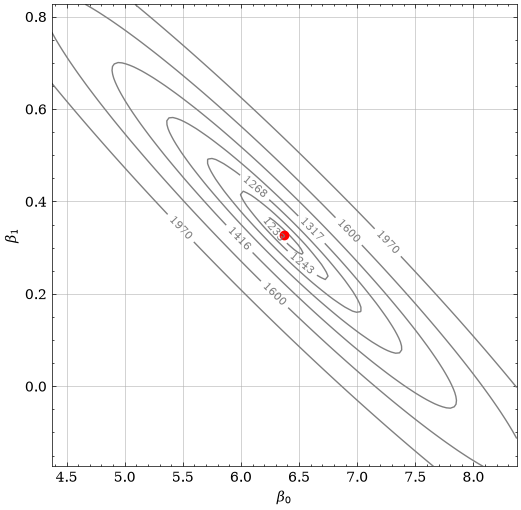

In [6]:
def plot_rss_landscape(df, x_axis, y_axis, b0_spread=2.0, b1_spread=0.5, n=120):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis].astype(float)).to_numpy()
    y = np.log10(df.loc[mask, y_axis].astype(float)).to_numpy()

    b1_hat, b0_hat = np.polyfit(x, y, 1)                       # OLS optimum
    rss_min = np.sum((y - (b0_hat + b1_hat * x)) ** 2)

    b0 = np.linspace(b0_hat - b0_spread, b0_hat + b0_spread, n)
    b1 = np.linspace(b1_hat - b1_spread, b1_hat + b1_spread, n)
    B0, B1 = np.meshgrid(b0, b1)
    resid = y[:, None, None] - (B0[None] + B1[None] * x[:, None, None])
    RSS = np.sum(resid ** 2, axis=0)
    
    fig, axs = plt.subplots(figsize=(6, 6))
    levels = rss_min * np.array([1.002, 1.01, 1.03, 1.07, 1.15, 1.3, 1.6])
    cs = axs.contour(B0, B1, RSS, levels=levels, colors='grey', linewidths=1)
    axs.clabel(cs, inline=True, fontsize=8, fmt='%.0f')
    axs.plot(b0_hat, b1_hat, 'o', color='red', ms=6)
    axs.set_xlabel(r'$\beta_0$'); axs.set_ylabel(r'$\beta_1$')
    save_figure(3, 3, 'rss_surface', variant='contour')

    plt.show()   

plot_rss_landscape(df, 'No Homeless', 'Total Damages (US$)')

**Fig. 3.4** Standard errors (bootstrap)

In [7]:
def animate_bootstrap_se(df, x_axis, y_axis,
                         n_boot=120, sample_frac=1.0, replace=True,
                         seed=0, fps=10, save_path=None):
    """
    Bootstrap the OLS coefficients to visualise their standard error.
    Each frame: draw one resample's fitted line (left) and add its (b0, b1) to
    the histograms (right). The spread of the collected coefficients == the
    (bootstrap) standard error of the estimates.
    """
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis].astype(float)).to_numpy()
    y = np.log10(df.loc[mask, y_axis].astype(float)).to_numpy()
    N = len(x)
    m = int(round(sample_frac * N))
    rng = np.random.default_rng(seed)

    b1_hat, b0_hat = np.polyfit(x, y, 1)
    b0s, b1s = np.empty(n_boot), np.empty(n_boot)
    idx_list = []
    for i in range(n_boot):
        idx = rng.choice(N, size=m, replace=replace)
        idx_list.append(idx)
        b1s[i], b0s[i] = np.polyfit(x[idx], y[idx], 1)

    se_b0, se_b1 = b0s.std(ddof=1), b1s.std(ddof=1)
    x_line = np.linspace(x.min(), x.max(), 100)

    fig = plt.figure(figsize=(13, 5))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.5, 1])
    axS = fig.add_subplot(gs[:, 0])
    ax0 = fig.add_subplot(gs[0, 1])
    ax1 = fig.add_subplot(gs[1, 1])
    
    plt.subplots_adjust(hspace=0.4)
    axS.scatter(x, y, s=18, marker='o', alpha=0.5, edgecolors='w',
                linewidth=0.4, color='steelblue', zorder=1)
    axS.plot(x_line, b0_hat + b1_hat * x_line, color='black', lw=2.5,
             label='full-sample OLS fit', zorder=4)
    picked = axS.scatter([], [], s=28, color='red', alpha=0.7,
                         edgecolors='darkred', linewidth=0.4, zorder=3,
                         label='sampled points')
    cur_line, = axS.plot([], [], color='red', lw=2, zorder=5)
    axS.set_xticks(np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]))
    axS.set_xticklabels(['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$', '$10^6$'])
    axS.set_xlabel(x_axis); axS.set_ylabel(y_axis)
    axS.legend(loc='lower right')

    r0 = (b0s.min(), b0s.max()); r1 = (b1s.min(), b1s.max())
    for ax, hat, se, lab in [(ax0, b0_hat, se_b0, r'$\beta_0$'),
                             (ax1, b1_hat, se_b1, r'$\beta_1$')]:
        ax.axvline(hat, color='black', lw=2)
        ax.set_ylabel('count'); ax.set_xlabel(lab)

    def draw_hists(k):
        ax0.cla(); ax1.cla()
        ax0.hist(b0s[:k+1], bins=20, range=r0, color='salmon', edgecolor='w')
        ax1.hist(b1s[:k+1], bins=20, range=r1, color='salmon', edgecolor='w')
        for ax, hat, se, samp, lab in [
            (ax0, b0_hat, se_b0, b0s[:k+1], r'$\beta_0$'),
            (ax1, b1_hat, se_b1, b1s[:k+1], r'$\beta_1$')]:
            ax.axvline(hat, color='black', lw=2, label='full-sample')
            ax.axvspan(hat - se, hat + se, color='gray', alpha=0.2)
            ax.set_xlabel(lab); ax.set_ylabel('count')
            ax.set_title(fr'SE {lab} = {samp.std(ddof=1):.3f}', fontsize=10)

    def update(k):
        idx = np.unique(idx_list[k])          
        picked.set_offsets(np.column_stack([x[idx], y[idx]]))
        cur_line.set_data(x_line, b0s[k] + b1s[k] * x_line)
        axS.plot(x_line, b0s[k] + b1s[k] * x_line, color='red',
                 lw=0.5, alpha=0.08, zorder=2)
        draw_hists(k)
        fig.suptitle(f'Sample {k+1}/{n_boot}'
                     f'    final SE: $\\beta_0$={se_b0:.3f}, $\\beta_1$={se_b1:.3f}')
        return ()

    anim = FuncAnimation(fig, update, frames=n_boot, interval=1000/fps)
    if save_path:
        anim.save(save_path, writer=PillowWriter(fps=fps))
    plt.close(fig)
    print(f'b0 = {b0_hat:.3f}  SE $\hat{{\beta}}_0$ = {se_b0:.3f}')
    print(f'b1 = {b1_hat:.3f}  SE $\hat{{\beta}}_1$ = {se_b1:.3f}')
    return anim, (b0s, b1s)


anim, (b0s, b1s) = animate_bootstrap_se(df, 'No Homeless', 'Total Damages (US$)',n_boot=120, sample_frac=1.0, replace=True, seed=0, fps=10,)
os.makedirs(os.path.join(figure_path,'3.4_standard_errors'),exist_ok=True)
anim.save(os.path.join(figure_path, '3.4_standard_errors', '3.4_standard_errors.gif'), writer=PillowWriter(fps=10))
HTML(anim.to_jshtml())   

b0 = 6.373  SE $\hateta}_0$ = 0.125
b1 = 0.327  SE $\hateta}_1$ = 0.032


<>:81: SyntaxWarning: invalid escape sequence '\h'
<>:82: SyntaxWarning: invalid escape sequence '\h'
<>:81: SyntaxWarning: invalid escape sequence '\h'
<>:82: SyntaxWarning: invalid escape sequence '\h'
/var/folders/ct/qpfxjbdn1xx4fvb2v099sg_00000gn/T/ipykernel_26398/708941820.py:81: SyntaxWarning: invalid escape sequence '\h'
  print(f'b0 = {b0_hat:.3f}  SE $\hat{{\beta}}_0$ = {se_b0:.3f}')
/var/folders/ct/qpfxjbdn1xx4fvb2v099sg_00000gn/T/ipykernel_26398/708941820.py:82: SyntaxWarning: invalid escape sequence '\h'
  print(f'b1 = {b1_hat:.3f}  SE $\hat{{\beta}}_1$ = {se_b1:.3f}')
/Users/larsboecking/Documents/01_Code/Statistical_Learning_TUM/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/larsboecking/Documents/01_Code/Statistical_Learning_TUM/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in sca

**Fig. 3.5** confidence bands

Saved Fig. 3.5 -> 03_figures/3.5_confidence_band/3.5_confidence_band_No_Homeless_Total_Damages_US_deg1.pdf
Saved Fig. 3.5 -> 03_figures/3.5_confidence_band/3.5_confidence_band_No_Homeless_Total_Damages_US_deg1.svg


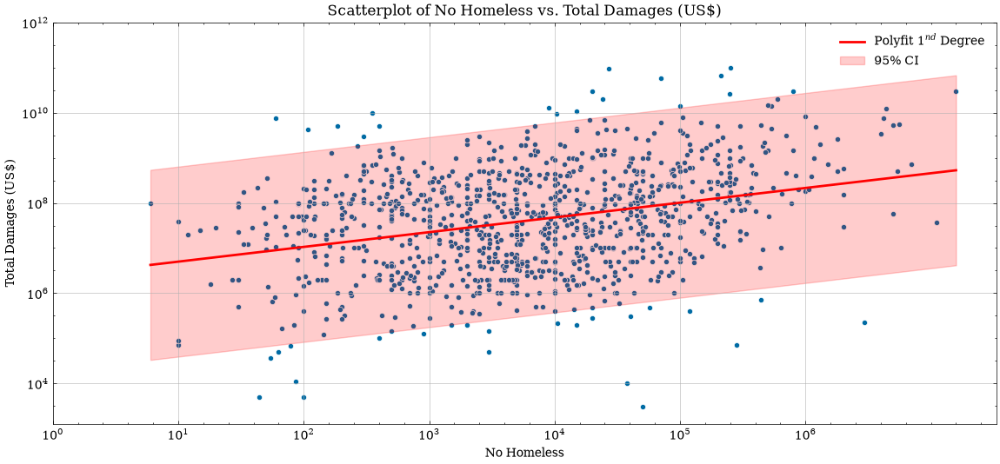

In [8]:
def _plot_scatter_confidence(df, x_axis, y_axis, fit_polyfit, n=1, conf_alpha=0.2):
    mask = (df[x_axis] > 0) & (df[y_axis] > 0)
    x = np.log10(df.loc[mask, x_axis])
    y = np.log10(df.loc[mask, y_axis])

    plt.scatter(x, y, s=20, marker="o", alpha=1, edgecolors="w", linewidth=0.5)

    if fit_polyfit:
        coefficients = np.polyfit(x, y, n)
        poly = np.poly1d(coefficients)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = poly(x_fit)

        y_pred = poly(x)
        residuals = y - y_pred
        std_err = residuals.std()
        ci = 1.96 * std_err

        plt.plot(
            x_fit, y_fit, color="red", linewidth=2, label=f"Polyfit ${n}^{{nd}}$ Degree"
        )
        plt.fill_between(
            x_fit, y_fit - ci, y_fit + ci, color="red", alpha=conf_alpha, label="95% CI"
        )

    plt.xticks(
        ticks=np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]),
        labels=["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$", "$10^5$", "$10^6$"],
    )
    plt.yticks(
        ticks=np.log10([1e4, 1e6, 1e8, 1e10, 1e12]),
        labels=["$10^4$", "$10^6$", "$10^8$", "$10^{10}$", "$10^{12}$"],
    )
    plt.legend()
    plt.xlabel(f"{x_axis}")
    plt.ylabel(f"{y_axis}")
    plt.title(f"Scatterplot of {x_axis} vs. {y_axis}")
    save_figure(3, 5, "confidence_band", variant=f"{x_axis}_{y_axis}_deg{n}")
    plt.show()


x_axis = "No Homeless"
y_axis = "Total Damages (US$)"
fit_polyfit = True
_plot_scatter_confidence(df, x_axis, y_axis, fit_polyfit, n=1)

In [9]:
features = [
        "No Homeless",
        ]
target = "Total Damages (US$)"

X = np.log10(df[features])
y = np.log10(df[target])

valid = ~(
    X.isnull().any(axis=1)
    | X.isin([np.inf, -np.inf]).any(axis=1)
    | y.isnull()
    | y.isin([np.inf, -np.inf])
)
X = X[valid]
y = y[valid]

X = sm.add_constant(X)

model = sm.OLS(y.astype(float), X.astype(float)).fit()
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     Total Damages (US$)   R-squared:                       0.103
Model:                             OLS   Adj. R-squared:                  0.102
Method:                  Least Squares   F-statistic:                     121.8
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           6.92e-27
Time:                         23:17:24   Log-Likelihood:                -1590.3
No. Observations:                 1067   AIC:                             3185.
Df Residuals:                     1065   BIC:                             3195.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           6.3726      0.117     54

In [10]:
features = [
        "No Homeless",
        # "Total Deaths",
        # "No Injured",
        ]
target = "Total Damages (US$)"

X = np.log10(df[features])
y = np.log10(df[target])

valid = ~(
    X.isnull().any(axis=1)
    | X.isin([np.inf, -np.inf]).any(axis=1)
    | y.isnull()
    | y.isin([np.inf, -np.inf])
)
X = X[valid]
y = y[valid]

X = sm.add_constant(X)

model = sm.OLS(y.astype(float), X.astype(float)).fit()
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     Total Damages (US$)   R-squared:                       0.103
Model:                             OLS   Adj. R-squared:                  0.102
Method:                  Least Squares   F-statistic:                     121.8
Date:                 Tue, 13 Oct 2026   Prob (F-statistic):           6.92e-27
Time:                         23:17:24   Log-Likelihood:                -1590.3
No. Observations:                 1067   AIC:                             3185.
Df Residuals:                     1065   BIC:                             3195.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           6.3726      0.117     54

**Fig. 3.6 / 3.7** Dummy variables and interaction terms

Saved Fig. 3.6 -> 03_figures/3.6_dummy_variables/3.6_dummy_variables_Wildfire_linFalse.pdf
Saved Fig. 3.6 -> 03_figures/3.6_dummy_variables/3.6_dummy_variables_Wildfire_linFalse.svg


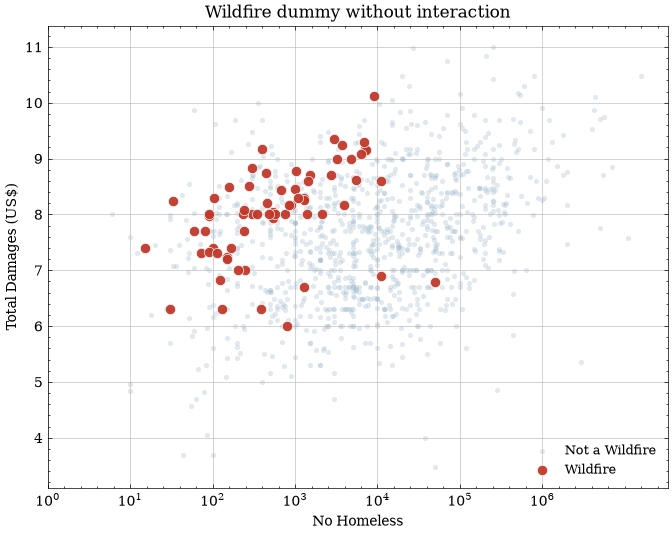

Saved Fig. 3.6 -> 03_figures/3.6_dummy_variables/3.6_dummy_variables_Wildfire_linTrue.pdf
Saved Fig. 3.6 -> 03_figures/3.6_dummy_variables/3.6_dummy_variables_Wildfire_linTrue.svg


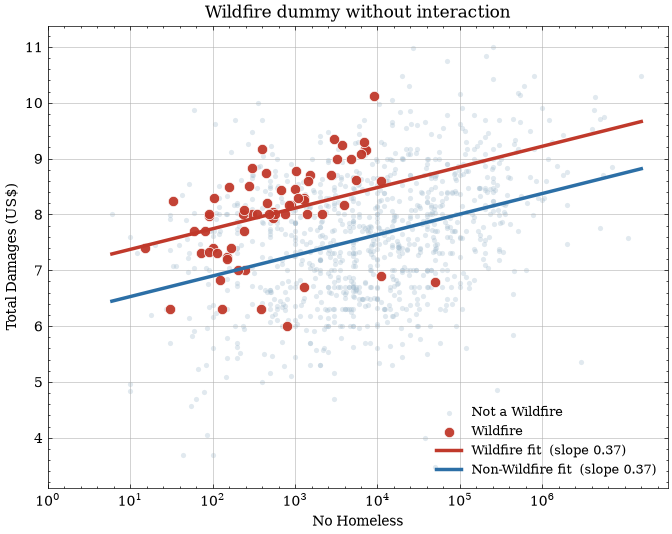

Saved Fig. 3.7 -> 03_figures/3.7_interactions/3.7_interactions_Wildfire_linTrue.pdf
Saved Fig. 3.7 -> 03_figures/3.7_interactions/3.7_interactions_Wildfire_linTrue.svg


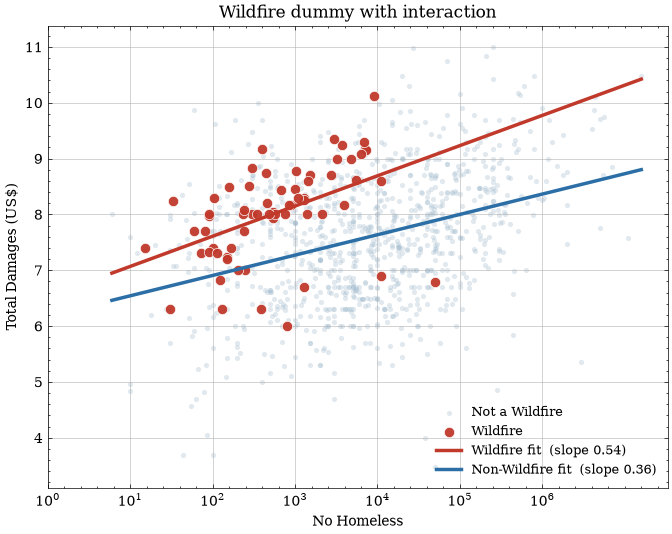

In [11]:
def plot_disaster_dummy(df, x_axis="No Homeless", y_axis="Total Damages (US$)",
                        disaster_type="Wildfire", plot_linear_regressions=False,
                        interaction=False):
    x = np.log10(df[x_axis].astype(float))
    y = np.log10(df[y_axis].astype(float))
    d = (df["Disaster Type"] == disaster_type).astype(float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y, d = x[valid], y[valid], d[valid]

    cols = {"isType": d, "logX": x}
    if interaction:
        cols["type_logX"] = d * x        
    X = sm.add_constant(pd.DataFrame(cols))
    res = sm.OLS(y, X).fit()
    p = res.params
    b0, b1, b2 = p["const"], p["isType"], p["logX"]
    b3 = p.get("type_logX", 0.0)           #

    fig, ax = plt.subplots(figsize=(8, 6))
    for is_t, color, s, al, z in [(0, "#9DB8CC", 14, 0.30, 1), (1, "#C0392B", 55, 0.95, 3)]:
        m = d == is_t
        ax.scatter(x[m], y[m], s=s, alpha=al, color=color, edgecolors="white",
                   linewidth=0.5 if is_t else 0, zorder=z,
                   label=disaster_type if is_t else f"Not a {disaster_type}")

    if plot_linear_regressions:
        xl = np.linspace(x.min(), x.max(), 100)
        ax.plot(xl, (b0 + b1) + (b2 + b3) * xl, color="#C0392B", lw=2.5, zorder=4,
                label=f"{disaster_type} fit  (slope {b2 + b3:.2f})")
        ax.plot(xl, b0 + b2 * xl, color="#2C6FA6", lw=2.5, zorder=4,
                label=f"Non-{disaster_type} fit  (slope {b2:.2f})")

    ax.set_xticks(np.log10([1e0, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6]))
    ax.set_xticklabels(["$10^0$", "$10^1$", "$10^2$", "$10^3$", "$10^4$", "$10^5$", "$10^6$"])
    ax.set_xlabel(x_axis); ax.set_ylabel(y_axis)
    ax.set_title(f"{disaster_type} dummy {'with' if interaction else 'without'} interaction")
    ax.legend(loc="lower right", fontsize=9)
    
    save_figure(3, 7 if interaction else 6, 'interactions' if interaction else 'dummy_variables', variant=f'{disaster_type}_lin{plot_linear_regressions}')
    plt.show()
    return res

plot_disaster_dummy(df, disaster_type="Wildfire", plot_linear_regressions=False)
plot_disaster_dummy(df, disaster_type="Wildfire", plot_linear_regressions=True)
plot_disaster_dummy(df, disaster_type="Wildfire", plot_linear_regressions=True, interaction=True)

**Fig. 3.8 / 3.9** Ridge and Lasso coefficient paths

Saved Fig. 3.8 -> 03_figures/3.8_ridge/3.8_ridge.pdf
Saved Fig. 3.8 -> 03_figures/3.8_ridge/3.8_ridge.svg


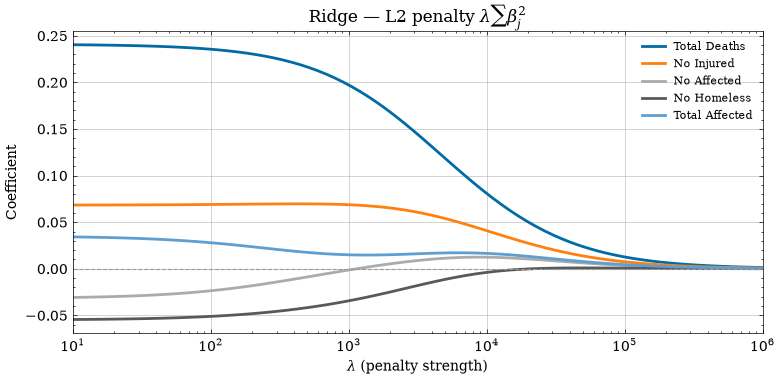

Saved Fig. 3.9 -> 03_figures/3.9_lasso/3.9_lasso.pdf
Saved Fig. 3.9 -> 03_figures/3.9_lasso/3.9_lasso.svg


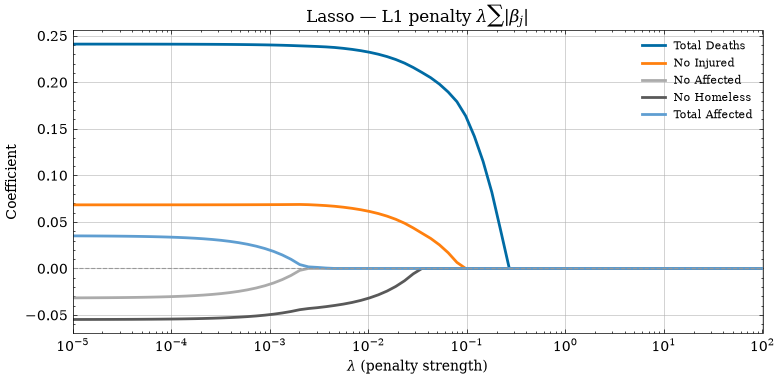

In [12]:
def plot_shrinkage_path(df, method="ridge", preds=None, target="Total Damages (US$)", a_axis_limit=(-5, 5)):
    preds = preds or ["Total Deaths", "No Injured", "No Affected", "No Homeless", "Total Affected"]
    d = df.dropna(subset=[target]).copy()
    d = d[d[target] > 0]
    X = np.log1p(d[preds].apply(pd.to_numeric, errors="coerce").fillna(0.0).astype(float))
    y = np.log10(d[target].astype(float))

    Xs = StandardScaler().fit_transform(X)
    ys = y - y.mean()

    estimators = {
        "ridge": (lambda l: Ridge(alpha=l),                  r"Ridge — L2 penalty $\lambda\sum\beta_j^2$"),
        "lasso": (lambda l: Lasso(alpha=l, max_iter=50000),  r"Lasso — L1 penalty $\lambda\sum|\beta_j|$"),
    }
    make, title = estimators[method]

    lambdas = np.logspace(a_axis_limit[0], a_axis_limit[1], 80)
    paths = np.array([make(l).fit(Xs, ys).coef_ for l in lambdas])

    fig, a = plt.subplots(figsize=(8, 4))
    for j, p in enumerate(preds):
        a.plot(lambdas, paths[:, j], lw=2, label=p)
    a.axhline(0, color="#999", lw=0.8, ls="--")
    a.set_xscale("log")
    a.set_xlim(*lambdas[[0, -1]])
    a.set_xlabel(r"$\lambda$ (penalty strength)"); a.set_ylabel("Coefficient")
    a.set_title(title)
    a.legend(loc="upper right", fontsize=8, framealpha=0.9)
    plt.tight_layout()
    save_figure(3, 9 if method == 'lasso' else 8, method)
    plt.show()

plot_shrinkage_path(df, method="ridge",a_axis_limit=(1, 6))
plot_shrinkage_path(df, method="lasso",a_axis_limit=(-5, 2))

**Fig. 3.10** Constraint geometry

Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_1.pdf
Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_1.svg


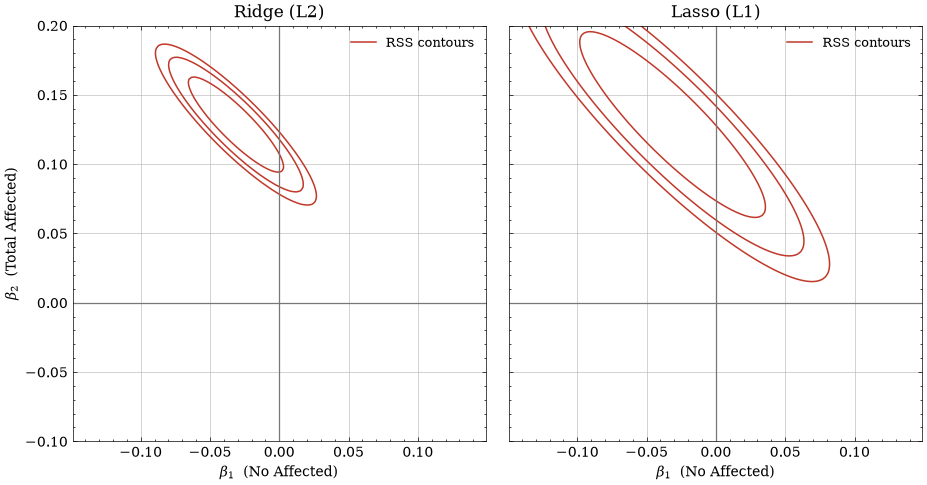

Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_2.pdf
Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_2.svg


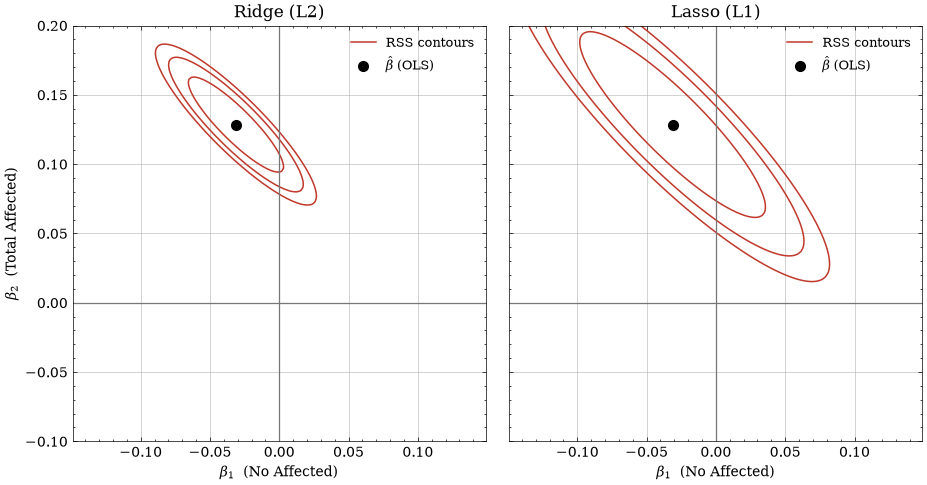

Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_3.pdf
Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_3.svg


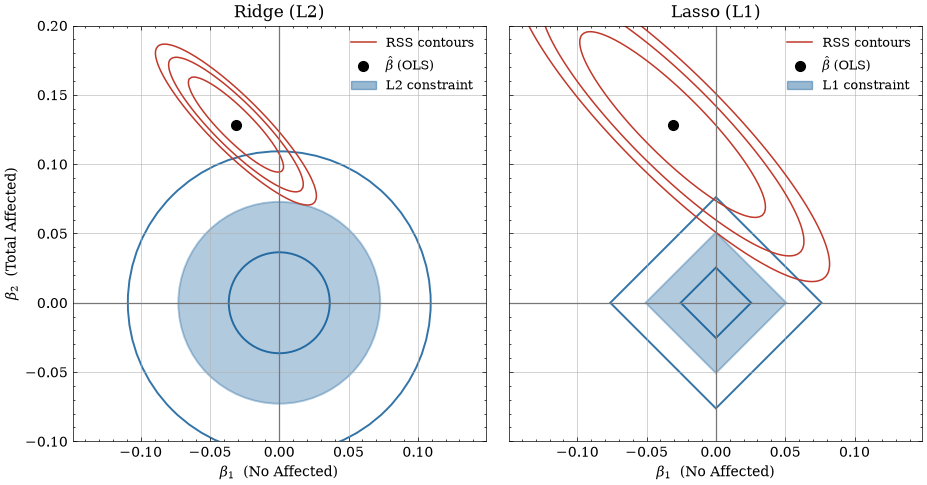

Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_4.pdf
Saved Fig. 3.10 -> 03_figures/3.10_constraint_geometry/3.10_constraint_geometry_4.svg


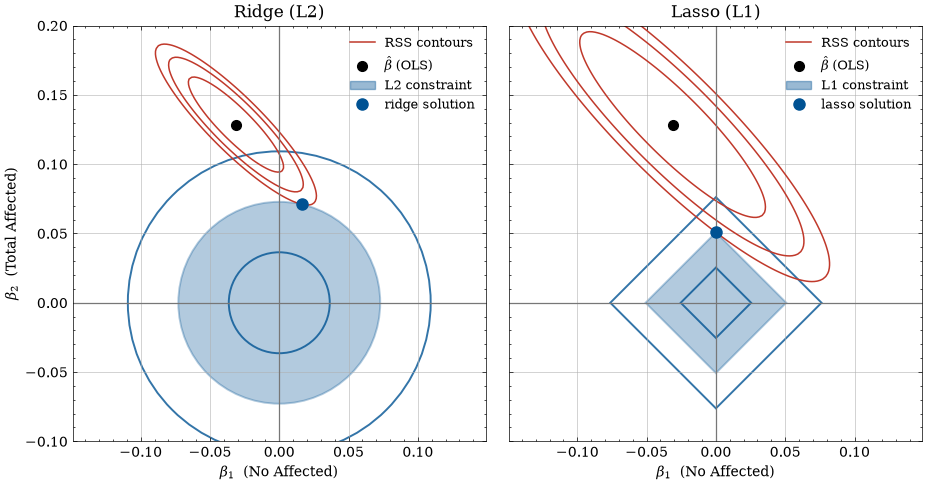

In [13]:
def plot_constraint_geometry(df, p1="No Affected", p2="Total Affected",
                             target="Total Damages (US$)", lasso_alpha=0.05,
                             show_rss=True, show_ols=False,
                             show_constraint=False, show_solution=False,
                             constraint_factors=(0.5, 1.0, 1.5), save=None):
    d = df.dropna(subset=[target]).copy(); d = d[d[target] > 0]
    X = np.log1p(d[[p1, p2]].apply(pd.to_numeric, errors="coerce").fillna(0.0).astype(float))
    y = np.log10(d[target].astype(float))
    Z = StandardScaler().fit_transform(X)
    ys = y.values - y.values.mean()

    b_ols = LinearRegression(fit_intercept=False).fit(Z, ys).coef_
    b_l   = Lasso(alpha=lasso_alpha, fit_intercept=False, max_iter=100000).fit(Z, ys).coef_
    target_r = 0.55 * np.linalg.norm(b_ols)
    alphas = np.logspace(0, 6, 400)
    path = [Ridge(alpha=a, fit_intercept=False).fit(Z, ys).coef_ for a in alphas]
    b_r = path[int(np.argmin([abs(np.linalg.norm(b) - target_r) for b in path]))]

    A = Z.T @ Z; c = Z.T @ ys; c0 = ys @ ys
    g = np.linspace(-0.4, 0.4, 400); B1, B2 = np.meshgrid(g, g)
    R = c0 - 2*(B1*c[0] + B2*c[1]) + (A[0,0]*B1**2 + 2*A[0,1]*B1*B2 + A[1,1]*B2**2)
    rss = lambda b: c0 - 2*b@c + b@A@b
    CON = "#005293"

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharex=True, sharey=True)
    plt.subplots_adjust(wspace=0.05)

    for ax, sol, kind, title in [(axes[0], b_r, "ridge", "Ridge (L2)"),
                                 (axes[1], b_l, "lasso", "Lasso (L1)")]:
        handles = []

        if show_rss:
            base = rss(sol); rmin = rss(b_ols)
            inner = [rmin + (base - rmin) * f for f in (0.35, 0.70)]
            ax.contour(B1, B2, R, levels=sorted({*inner, base}), colors="#C0392B", linewidths=1.1)
            handles.append(Line2D([], [], color="#C0392B", lw=1.1, label="RSS contours"))

        ax.axhline(0, color="#777", lw=0.9); ax.axvline(0, color="#777", lw=0.9)

        if show_ols:
            ax.plot(*b_ols, "o", color="black", ms=7, zorder=4)
            handles.append(Line2D([], [], marker="o", color="black", ls="", ms=7, label=r"$\hat\beta$ (OLS)"))

        if show_constraint:
            s = abs(sol).sum() if kind == "lasso" else np.linalg.norm(sol)
            for f in constraint_factors:
                tangent = abs(f - 1.0) < 1e-9          
                if kind == "lasso":
                    verts = [(s*f, 0), (0, s*f), (-s*f, 0), (0, -s*f)]
                    ax.add_patch(plt.Polygon(verts, closed=True, fill=tangent,
                                             facecolor=CON if tangent else "none",
                                             edgecolor=CON, alpha=0.3 if tangent else 0.8, lw=1.4, zorder=1))
                else:
                    ax.add_patch(plt.Circle((0, 0), s*f, fill=tangent,
                                            facecolor=CON if tangent else "none",
                                            edgecolor=CON, alpha=0.3 if tangent else 0.8, lw=1.4, zorder=1))
            handles.append(Patch(facecolor=CON, edgecolor=CON, alpha=0.4,
                                 label=f"{'L1' if kind=='lasso' else 'L2'} constraint"))

        if show_solution:
            ax.plot(*sol, "o", color=CON, ms=8, zorder=5)
            handles.append(Line2D([], [], marker="o", color=CON, ls="", ms=8, label=f"{kind} solution"))

        ax.set_xlim(-0.149, 0.149); ax.set_ylim(-0.1, 0.2)
        ax.set_xlabel(rf"$\beta_1$  ({p1})")
        if ax == axes[0]:
            ax.set_ylabel(rf"$\beta_2$  ({p2})")
        ax.set_title(title); ax.set_aspect("equal")
        if handles:
            ax.legend(handles=handles, loc="upper right", fontsize=9)

    if save:
        save_figure(3, 10, 'constraint_geometry', variant=str(save).replace('.pdf', '').replace('constraint_geometry_', ''))
    plt.show()
    
plot_constraint_geometry(df, save="constraint_geometry_1.pdf")               
plot_constraint_geometry(df, show_ols=True, save="constraint_geometry_2.pdf")
plot_constraint_geometry(df, show_ols=True, show_constraint=True, save="constraint_geometry_3.pdf")     
plot_constraint_geometry(df, show_ols=True, show_constraint=True, show_solution=True, save="constraint_geometry_4.pdf")

**Fig. 3.11** Penalised regression in one dimension: RSS, penalty and objective (L1, then L2)

beta_hat = 0.101, RSS_min = 6904, lasso optimum is 0 for lambda >= 1057
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_rss.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_rss.svg


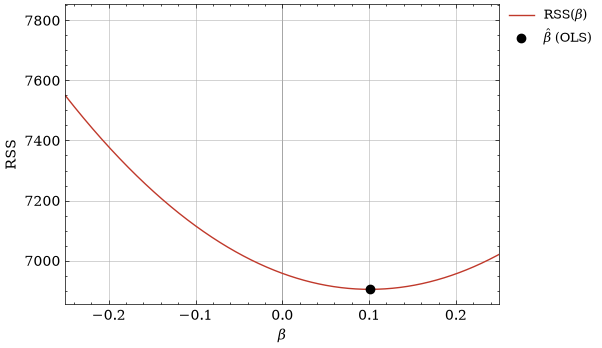

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_penalty.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_penalty.svg


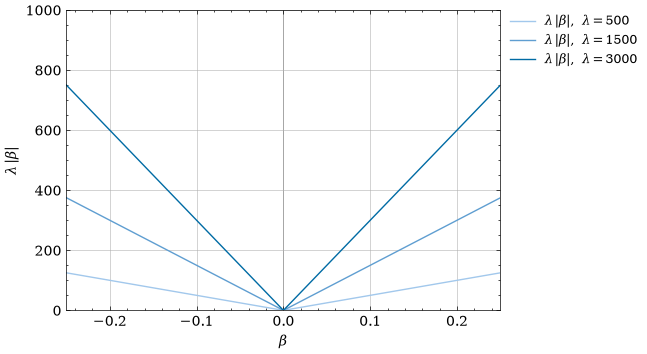

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_combined_single.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_combined_single.svg


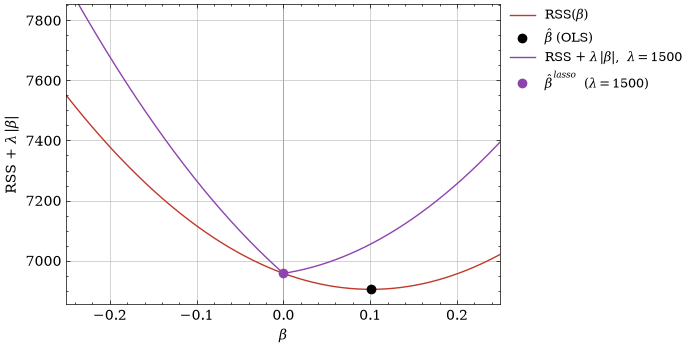

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_combined_three.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l1_combined_three.svg


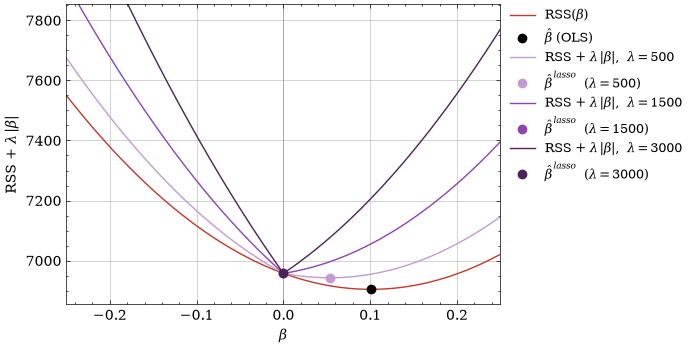

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_penalty.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_penalty.svg


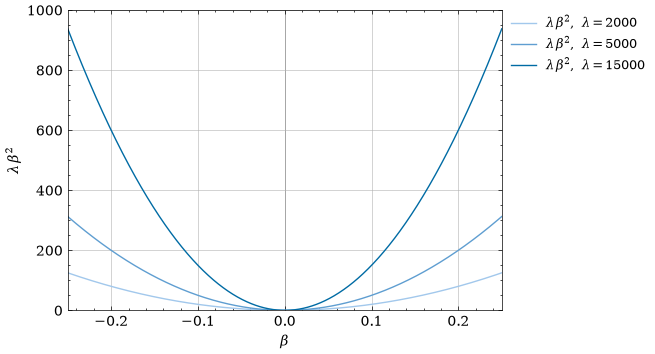

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_combined_single.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_combined_single.svg


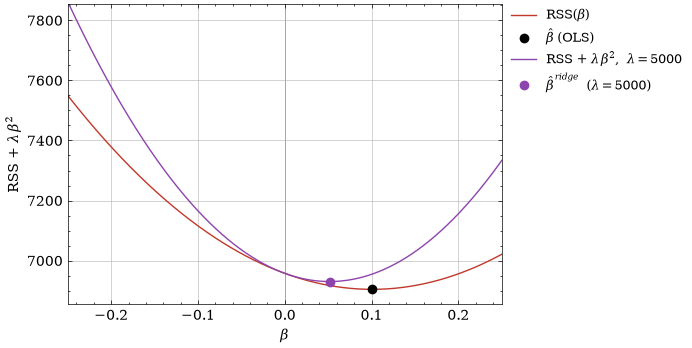

Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_combined_three.pdf
Saved Fig. 3.11 -> 03_figures/3.11_penalised_1d/3.11_penalised_1d_l2_combined_three.svg


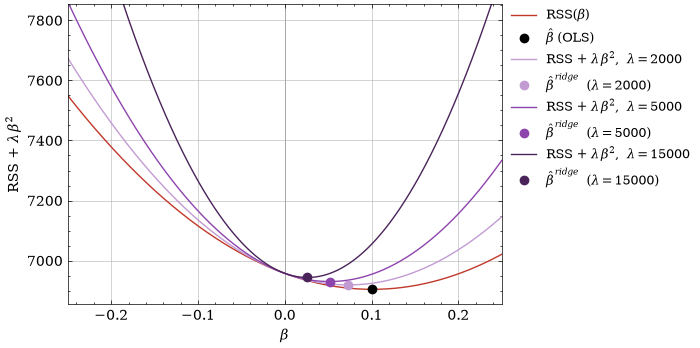

In [14]:
from typing import Callable

from matplotlib.lines import Line2D
from matplotlib.colors import LightSource, LinearSegmentedColormap, to_rgb

# --- Shared conventions for Fig. 3.11 (1-D) and Fig. 3.12 (3-D) ------------------
# RSS is always red, the OLS optimum always a black dot. Penalties are blue and the
# penalised objectives purple, light -> dark with increasing lambda. Each penalised
# optimum is a dot in the colour of its objective and gets its own legend entry.
PEN_RSS_COL, PEN_OLS_COL = "#C0392B", "black"
PEN_BLUES = ["#A2C8EC", "#5F9ED1", "#006BA4"]
PEN_PURPLES = ["#C39BD3", "#8E44AD", "#4A235A"]
PEN_MS = 6


def prepare_penalised_design(df: pd.DataFrame, p1: str = "No Affected", p2: str = "Total Affected",
                             target: str = "Total Damages (US$)") -> tuple[np.ndarray, np.ndarray]:
    """Return the standardised design ``Z`` (n x 2) and centred log-target ``ys``.

    Identical to the preparation in Fig. 3.10, so all penalised optima agree with
    the constraint-geometry figure: log1p of both predictors, standardised; log10
    of the target, centred; no intercept.
    """
    d = df.dropna(subset=[target]).copy()
    d = d[d[target] > 0]
    X = np.log1p(d[[p1, p2]].apply(pd.to_numeric, errors="coerce").fillna(0.0).astype(float))
    y = np.log10(d[target].astype(float))
    Z = StandardScaler().fit_transform(X)
    return Z, y.values - y.values.mean()


def _dot_handle(color: str, label: str) -> Line2D:
    """Legend handle for a filled marker without a line."""
    return Line2D([], [], marker="o", color=color, ls="", ms=PEN_MS, label=label)


def plot_penalised_1d(df: pd.DataFrame, predictor_index: int = 1,
                      lambdas: dict[str, tuple[int, int, int]] = {"l1": (500, 1500, 3000), "l2": (2000, 5000, 15000)},
                      b_range: float = 0.25, yspan: float = 1000.0, figsize: tuple[float, float] = (5.6, 3.9),
                      save: bool = True) -> None:
    """Fig. 3.11: RSS, penalty and penalised objective for a single coefficient.

    Seven panels: ``rss``; then for each norm ``<key>_penalty`` (three lambdas),
    ``<key>_combined_single`` (middle lambda) and ``<key>_combined_three``. Every
    panel spans ``yspan`` units on the y-axis so heights are comparable.

    Args:
        df: Disaster data frame.
        predictor_index: Column of the standardised design used as the single
            predictor (``1`` is Total Affected).
        lambdas: Three penalty strengths per norm; the middle one is the single
            value shown in the ``combined_single`` panel.
        b_range: Half-width of the beta axis.
        yspan: Height of the y-axis window shared by all panels.
        figsize: Size of each single panel.
        save: Write PDF + SVG through ``save_figure``.
    """
    Z, ys = prepare_penalised_design(df)
    z = Z[:, predictor_index]
    c0, c, A = ys @ ys, z @ ys, z @ z
    b_hat = c / A
    rss: Callable[[np.ndarray], np.ndarray] = lambda b: c0 - 2 * b * c + A * b**2
    rss_min = rss(b_hat)
    b = np.linspace(-b_range, b_range, 1001)
    print(f"beta_hat = {b_hat:.3f}, RSS_min = {rss_min:.0f}, lasso optimum is 0 for lambda >= {2 * abs(c):.0f}")

    norms = {
        "l1": dict(pen=lambda lam, b: lam * np.abs(b), label=r"$\lambda\,|\beta|$", hat=r"$\hat\beta^{\,lasso}$",
                   argmin=lambda lam: np.sign(c) * max(abs(c) - lam / 2, 0.0) / A),
        "l2": dict(pen=lambda lam, b: lam * b**2, label=r"$\lambda\,\beta^2$", hat=r"$\hat\beta^{\,ridge}$",
                   argmin=lambda lam: c / (A + lam)),
    }

    def new_axes(ylabel: str, ylo: float):
        fig, ax = plt.subplots(figsize=figsize)
        ax.axvline(0, color="#999", lw=0.7, zorder=0)
        ax.set_xlabel(r"$\beta$"); ax.set_ylabel(ylabel)
        ax.set_xlim(-b_range, b_range); ax.set_ylim(ylo, ylo + yspan)
        return fig, ax

    def finish(fig, ax, handles: list, variant: str) -> None:
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9, borderaxespad=0)
        if save:
            save_figure(3, 11, "penalised_1d", variant=variant)
        plt.show()

    def draw_rss(ax) -> list:
        h_line, = ax.plot(b, rss(b), color=PEN_RSS_COL)
        ax.plot(b_hat, rss_min, "o", color=PEN_OLS_COL, ms=PEN_MS, zorder=5)
        h_line.set_label(r"RSS$(\beta)$")
        return [h_line, _dot_handle(PEN_OLS_COL, r"$\hat\beta$ (OLS)")]

    fig, ax = new_axes("RSS", rss_min - 0.05 * yspan)
    finish(fig, ax, draw_rss(ax), "rss")

    for key, nm in norms.items():
        lams = lambdas[key]
        fig, ax = new_axes(nm["label"], 0.0)
        handles = [ax.plot(b, nm["pen"](lam, b), color=col, label=rf"{nm['label']},  $\lambda = {lam}$")[0]
                   for lam, col in zip(lams, PEN_BLUES)]
        finish(fig, ax, handles, f"{key}_penalty")

        for tag, use in (("single", (lams[1],)), ("three", lams)):
            fig, ax = new_axes(rf"RSS $+$ {nm['label']}", rss_min - 0.05 * yspan)
            handles = draw_rss(ax)
            for lam, col in zip(lams, PEN_PURPLES):
                if lam not in use:
                    continue
                h, = ax.plot(b, rss(b) + nm["pen"](lam, b), color=col, label=rf"RSS $+$ {nm['label']},  $\lambda = {lam}$")
                bm = nm["argmin"](lam)
                ax.plot(bm, rss(bm) + nm["pen"](lam, bm), "o", color=col, ms=PEN_MS, zorder=6)
                handles += [h, _dot_handle(col, rf"{nm['hat']}  ($\lambda = {lam}$)")]
            finish(fig, ax, handles, f"{key}_combined_{tag}")


plot_penalised_1d(df)

**Fig. 3.12** Penalised objective as surfaces over $(\beta_1, \beta_2)$

n = 5245, lambda_ridge = 1000, lambda_lasso = 524
OLS [-0.031  0.129], ridge [0.015 0.074], lasso [0.    0.051]
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_rss.pdf
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_rss.svg


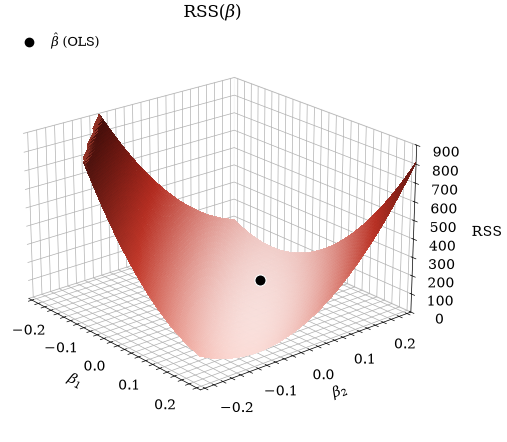

Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_l1_penalty.pdf
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_l1_penalty.svg


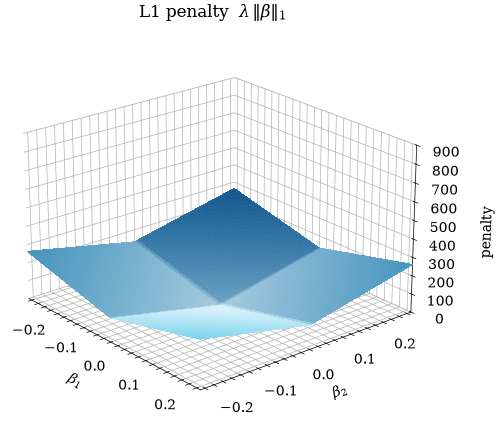

Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_lasso.pdf
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_lasso.svg


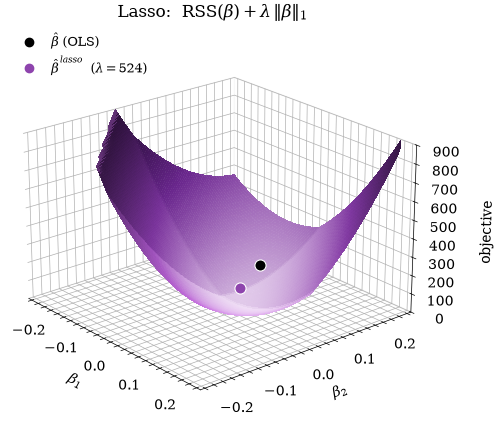

Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_l2_penalty.pdf
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_l2_penalty.svg


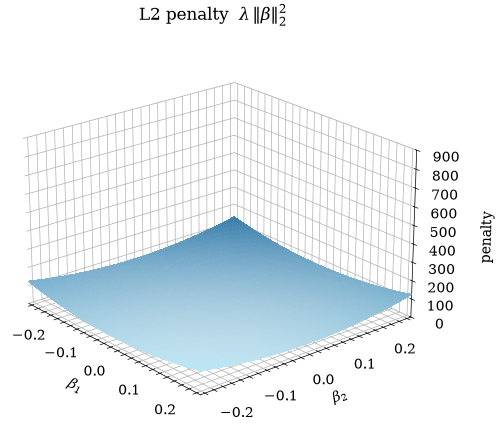

Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_ridge.pdf
Saved Fig. 3.12 -> 03_figures/3.12_penalised_surface/3.12_penalised_surface_ridge.svg


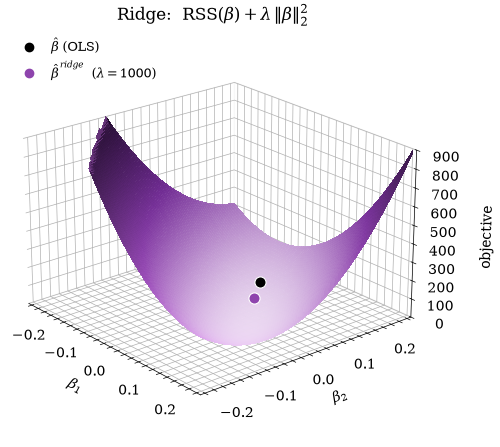

In [17]:
def _tint_cmap(color: str) -> LinearSegmentedColormap:
    """Light tint -> full colour -> dark shade of one hue, for shaded surfaces."""
    c = np.array(to_rgb(color))
    return LinearSegmentedColormap.from_list("tint", [1 - 0.35 * (1 - c), c, 0.55 * c])


def plot_penalised_surfaces(df: pd.DataFrame, lam_ridge: float = 1000.0, lasso_alpha: float = 0.05,
                            half: float = 0.25, n: int = 161, stride: int = 2, zcap: float = 900.0,
                            elev: float = 22, azim: float = -40, figsize: tuple[float, float] = (6.2, 5.4),
                            save: bool = True) -> None:
    """Fig. 3.12: RSS, penalty and penalised objective as surfaces over (beta_1, beta_2).

    Five panels on one grid, one view and one z-axis so the surfaces visibly add
    up: ``rss``, ``l1_penalty``, ``lasso``, ``l2_penalty``, ``ridge``. RSS is
    shifted so the OLS minimum sits at 0; a constant does not move the argmin.
    Heights above ``zcap`` are cut away so the flat valley stays visible.

    The default lambdas reproduce the optima of Fig. 3.10: ``lam_ridge`` is the
    ridge penalty in RSS units, and the lasso penalty is ``2 n lasso_alpha``
    because scikit-learn minimises ``RSS / (2n) + alpha ||beta||_1``.

    Args:
        df: Disaster data frame.
        lam_ridge: Ridge penalty strength in RSS units.
        lasso_alpha: scikit-learn ``Lasso`` alpha; converted to RSS units.
        half: Half-width of the beta grid.
        n: Grid points per axis (odd, so 0 lies on the grid and the L1 kink is sharp).
        stride: Draw every ``stride``-th grid line; keeps the SVG light for PowerPoint.
        zcap: Height at which the surfaces are cut.
        elev, azim: View angles.
        figsize: Size of each single panel.
        save: Write PDF + SVG through ``save_figure``.
    """
    Z, ys = prepare_penalised_design(df)
    N = len(ys)
    A, c, c0 = Z.T @ Z, Z.T @ ys, ys @ ys
    b_ols = LinearRegression(fit_intercept=False).fit(Z, ys).coef_
    lam_l1 = 2 * N * lasso_alpha
    b_lasso = Lasso(alpha=lasso_alpha, fit_intercept=False, max_iter=100000).fit(Z, ys).coef_
    b_ridge = Ridge(alpha=lam_ridge, fit_intercept=False).fit(Z, ys).coef_
    print(f"n = {N}, lambda_ridge = {lam_ridge:.0f}, lambda_lasso = {lam_l1:.0f}")
    print(f"OLS {b_ols.round(3)}, ridge {b_ridge.round(3)}, lasso {b_lasso.round(3)}")

    g = np.linspace(-half, half, n)
    B1, B2 = np.meshgrid(g, g)
    rss = lambda b1, b2: c0 - 2 * (b1 * c[0] + b2 * c[1]) + (A[0, 0] * b1**2 + 2 * A[0, 1] * b1 * b2 + A[1, 1] * b2**2)
    R = rss(B1, B2) - rss(*b_ols)
    P1, P2 = lam_l1 * (np.abs(B1) + np.abs(B2)), lam_ridge * (B1**2 + B2**2)
    light = LightSource(azdeg=225, altdeg=40)
    pen_col, sum_col = PEN_BLUES[2], PEN_PURPLES[1]

    def value_at(S: np.ndarray, b: np.ndarray) -> float:
        return float(S[np.argmin(abs(g - b[1])), np.argmin(abs(g - b[0]))])

    def panel(S: np.ndarray, color: str, title: str, zlabel: str, points: list, variant: str) -> None:
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111, projection="3d")
        Sm = np.where(S > zcap, np.nan, S)
        rgb = light.shade(np.nan_to_num(Sm, nan=zcap), cmap=_tint_cmap(color), vmin=0, vmax=zcap,
                          vert_exag=0.02 / half, blend_mode="soft")
        ax.plot_surface(B1, B2, Sm, facecolors=rgb, rstride=stride, cstride=stride, linewidth=0,
                        antialiased=False, alpha=0.95, shade=False)
        handles = []
        for b, col, label in points:
            ax.plot([b[0]], [b[1]], [value_at(S, b) + 0.015 * zcap], "o", color=col, ms=PEN_MS + 2,
                    markeredgecolor="white", markeredgewidth=0.8, zorder=10)
            handles.append(_dot_handle(col, label))
        ax.set_xlim(-half, half); ax.set_ylim(-half, half); ax.set_zlim(0, zcap)
        ax.set_xlabel(r"$\beta_1$", labelpad=4); ax.set_ylabel(r"$\beta_2$", labelpad=4)
        ax.set_zlabel(zlabel, labelpad=8)
        ax.set_title(title, pad=0)
        ax.view_init(elev=elev, azim=azim)
        ax.set_box_aspect((1, 1, 0.65))
        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.pane.fill = False
        if handles:
            ax.legend(handles=handles, loc="upper left", fontsize=9)
        if save:
            save_figure(3, 12, "penalised_surface", variant=variant)
        plt.show()

    ols = (b_ols, PEN_OLS_COL, r"$\hat\beta$ (OLS)")
    panel(R, PEN_RSS_COL, r"RSS$(\beta)$", r"RSS", [ols], "rss")
    panel(P1, pen_col, r"L1 penalty  $\lambda\,\|\beta\|_1$", "penalty", [], "l1_penalty")
    panel(R + P1, sum_col, r"Lasso:  RSS$(\beta) + \lambda\,\|\beta\|_1$", "objective",
          [ols, (b_lasso, sum_col, rf"$\hat\beta^{{\,lasso}}$  ($\lambda = {lam_l1:.0f}$)")], "lasso")
    panel(P2, pen_col, r"L2 penalty  $\lambda\,\|\beta\|_2^2$", "penalty", [], "l2_penalty")
    panel(R + P2, sum_col, r"Ridge:  RSS$(\beta) + \lambda\,\|\beta\|_2^2$", "objective",
          [ols, (b_ridge, sum_col, rf"$\hat\beta^{{\,ridge}}$  ($\lambda = {lam_ridge:.0f}$)")], "ridge")


plot_penalised_surfaces(df)